## Key Concepts Used in This Analysis

| Term | Plain-English Meaning |
|---|---|
| **Supervised** | The model is allowed to use the known answers (`species`) while learning. |
| **Feature (X)** | Information we give the model, such as bill length or body mass. |
| **Target (y)** | The answer we ultimately care about: the penguin's species. |
| **Class** | One possible target group: Adelie, Gentoo, or Chinstrap. |
| **Linear Discriminant (LD)** | A new blended feature created by LDA to help separate the species. |
| **Between-Class Scatter** | How far apart the different species groups are. More separation is better. |
| **Within-Class Scatter** | How spread out penguins of the same species are. Tighter groups are better. |
| **Scalings** | Weights showing how strongly the original features contribute to LD1 and LD2. |
| **Explained Separation** | How much of the species-separating information is captured by each LD. |
| **Target Leakage** | Accidentally giving the model the answer as an input feature. |
| **Data Leakage** | Letting Validation or Test information influence what the model learns. |

# Part 1 - Data Ingestion: Pre-Flight Check

## What This Step Does

Before changing the dataset, I first inspect what is actually available.

This check answers:

- How many penguin records are there?
- How many columns are available?
- What types of data are stored in those columns?
- Which columns contain missing values?
- Is the prediction target (`Species`) available?
- How many species must the model distinguish?
- Are there identifier, date, or note columns that should not be used as machine-learning features?

## Why It Matters

LDA requires a clearly defined target and clean numeric inputs.

Finding data-quality problems now prevents incorrect transformations later.

For this project:

**Target = Species**

The target represents the answer the model will eventually try to distinguish.

In [1]:
import pandas as pd
import numpy as np

# Load the Palmer Penguins dataset
df = pd.read_csv("../Data/penguins_raw.csv")

# Remove accidental spaces from column names
df.columns = df.columns.str.strip()

print("Dataset loaded successfully.")

Dataset loaded successfully.


## Part 1A - Dataset Size

This checks how much data is available.

- **Rows** = individual penguin records
- **Columns** = information recorded about each penguin

In [2]:
dataset_size = pd.DataFrame({
    "Measure": ["Penguin Records", "Columns"],
    "Count": [df.shape[0], df.shape[1]]
})

dataset_size

,Measure,Count
0,Penguin Records,344
1,Columns,17


### How to Read This

Each row represents one penguin record.

Each column represents one piece of information recorded about that penguin.

A dataset with **344 rows and 17 columns** means we currently have 344 observations described by 17 different fields.

## Part 1B - Preview the Raw Data

Before changing anything, I look at a few actual records.

This helps confirm that:

- the file loaded correctly
- the column names make sense
- numeric measurements appear numeric
- categorical values such as species and sex appear as expected
- missing values are visible

In [3]:
df.head()

,studyName,Sample Number,Species,Region,Island,Stage,Individual ID,Clutch Completion,Date Egg,Culmen Length (mm),Culmen Depth (mm),Flipper Length (mm),Body Mass (g),Sex,Delta 15 N (o/oo),Delta 13 C (o/oo),Comments
0,PAL0708,1,Adelie Penguin (Pygoscelis adeliae),Anvers,Torgersen,"Adult, 1 Egg Stage",N1A1,Yes,2007-11-11,39.1,18.7,181.0,3750.0,MALE,NaN,NaN,Not enough blood for isotopes.
1,PAL0708,2,Adelie Penguin (Pygoscelis adeliae),Anvers,Torgersen,"Adult, 1 Egg Stage",N1A2,Yes,2007-11-11,39.5,17.4,186.0,3800.0,FEMALE,8.94956,-24.69454,NaN
2,PAL0708,3,Adelie Penguin (Pygoscelis adeliae),Anvers,Torgersen,"Adult, 1 Egg Stage",N2A1,Yes,2007-11-16,40.3,18.0,195.0,3250.0,FEMALE,8.36821,-25.33302,NaN
3,PAL0708,4,Adelie Penguin (Pygoscelis adeliae),Anvers,Torgersen,"Adult, 1 Egg Stage",N2A2,Yes,2007-11-16,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Adult not sampled.
4,PAL0708,5,Adelie Penguin (Pygoscelis adeliae),Anvers,Torgersen,"Adult, 1 Egg Stage",N3A1,Yes,2007-11-16,36.7,19.3,193.0,3450.0,FEMALE,8.76651,-25.32426,NaN


### How to Read This Table

Each row is one penguin.

Examples of information recorded include:

- species
- island
- bill measurements
- flipper length
- body mass
- sex
- isotope measurements

`NaN` means a value is missing.

At this stage, missing values are **not a failure**. They are simply being identified so they can be handled correctly later.

## Part 1C - Data Types

Machine-learning tools treat numbers and text differently.

This step checks how Python currently understands every column.

### Common Types

- `float64` = decimal number
- `int64` = whole number
- `object` / `str` = text or category

In [4]:
type_summary = (
    df.dtypes
    .astype(str)
    .value_counts()
    .rename_axis("Python Data Type")
    .reset_index(name="Number of Columns")
)

type_summary

,Python Data Type,Number of Columns
0,str,10
1,float64,6
2,int64,1


In [5]:
column_types = pd.DataFrame({
    "Column": df.columns,
    "Python Type": df.dtypes.astype(str).values
})

column_types["Meaning"] = column_types["Python Type"].map({
    "float64": "Decimal Number",
    "int64": "Whole Number",
    "object": "Text / Category",
    "str": "Text / Category"
})

column_types

,Column,Python Type,Meaning
0,studyName,str,Text / Category
1,Sample Number,int64,Whole Number
2,Species,str,Text / Category
3,Region,str,Text / Category
4,Island,str,Text / Category
5,Stage,str,Text / Category
6,Individual ID,str,Text / Category
7,Clutch Completion,str,Text / Category
8,Date Egg,str,Text / Category
9,Culmen Length (mm),float64,Decimal Number


### What This Means

The dataset contains a mixture of:

- numeric measurements
- whole-number identifiers/counters
- text categories

LDA ultimately requires numeric input features.

The text categories will therefore need to be converted into numeric form later, while identifiers and dates will be removed rather than encoded.

## Part 1D - Missing Value Check

Missing values are blank pieces of information.

LDA cannot process missing values directly, so we need to know where the gaps exist before modeling.

This step only identifies the problem.

**No values are changed yet.**

In [6]:
missing = df.isnull().sum()
missing = missing[missing > 0]

missing_table = pd.DataFrame({
    "Column": missing.index,
    "Missing Values": missing.values,
    "Missing (%)": (missing.values / len(df) * 100).round(2)
})

missing_table

,Column,Missing Values,Missing (%)
0,Culmen Length (mm),2,0.58
1,Culmen Depth (mm),2,0.58
2,Flipper Length (mm),2,0.58
3,Body Mass (g),2,0.58
4,Sex,11,3.20
5,Delta 15 N (o/oo),14,4.07
6,Delta 13 C (o/oo),13,3.78
7,Comments,290,84.30


# Activity 3B - Linear Discriminant Analysis
Objective / Why LDA / Workflow
↓
## Key Concepts Used in This Analysis
↓
# Part 1 - Data Ingestion

## Palmer Penguins Classification Analysis

### Objective

This analysis uses **Linear Discriminant Analysis (LDA)** to reduce the number of input features while keeping the information that best separates the three penguin species.

The business-style question is:

**Can we simplify the dataset while still keeping enough information to clearly distinguish Adelie, Gentoo, and Chinstrap penguins?**

### Why LDA?

LDA is a supervised dimensionality-reduction method.

This means it uses the known species labels while deciding how to combine the original features.

Unlike PCA, which asks:

**"Where is the most variation in the data?"**

LDA asks:

**"Which combination of features separates the species most clearly?"**

For this dataset there are **3 species**, so LDA can create a maximum of:

**3 classes - 1 = 2 Linear Discriminants**

These will be called **LD1** and **LD2**.

---

### Analysis Workflow

The analysis will:

1. inspect and understand the raw data
2. remove identifier and date fields
3. separate the prediction target from the input features
4. split the data into Train, Validation, and Test sets
5. handle missing values
6. encode categorical information
7. examine feature relationships
8. standardize the features
9. apply LDA
10. evaluate different numbers of discriminants
11. perform one final Test evaluation
12. export the reduced dataset

### Understanding the Result

**How to read it:**  
`Missing Values` shows how many blank entries exist in each column.

`Missing (%)` shows how much of the full dataset is affected.

For example, `Comments` has **290 missing values**, meaning **84.30%** of that column is blank.

**What this result tells us:**  
Most of the measurement columns have very little missing data. Bill measurements, flipper length, and body mass are each missing in only **0.58%** of the records.

`Comments` is very different: more than four out of five records are blank.

**Why it matters:**  
The measurement fields still contain enough information to keep and can have their small number of missing values filled later.

`Comments` is mostly empty and is also free-text rather than a structured penguin measurement, so it is not useful as a model feature and will be removed.

## Part 1E - Target Check

The **target** is the answer the analysis is trying to distinguish.

For this dataset:

**Target = Species**

LDA is supervised, which means it uses these known species labels while learning how to separate the groups.

However, the Species column must remain separate from the input features.

Putting the answer directly into the feature matrix would create **target leakage**.

In [7]:
species_summary = (
    df["Species"]
    .value_counts()
    .reset_index()
)

species_summary.columns = ["Species", "Penguins"]

species_summary["Percent of Dataset"] = (
    species_summary["Penguins"] / len(df) * 100
).round(1)

species_summary

,Species,Penguins,Percent of Dataset
0,Adelie Penguin (Pygoscelis adeliae),152,44.2
1,Gentoo penguin (Pygoscelis papua),124,36.0
2,Chinstrap penguin (Pygoscelis antarctica),68,19.8


### What This Means

There are **3 penguin species** in the dataset.

LDA has an important limit:

**Maximum LDA components = number of classes - 1**

Therefore:

**3 species - 1 = maximum of 2 Linear Discriminants**

So even though the original dataset contains many features, LDA can eventually reduce them to only:

- LD1
- LD2

This is one of the biggest differences between PCA and LDA.

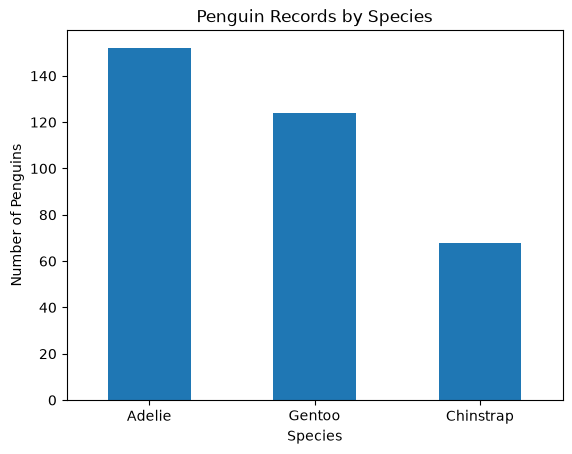

In [9]:
species_chart = species_summary.copy()

species_chart["Species Short"] = [
    "Adelie",
    "Gentoo",
    "Chinstrap"
]

species_chart.plot(
    x="Species Short",
    y="Penguins",
    kind="bar",
    legend=False
)

plt.title("Penguin Records by Species")
plt.xlabel("Species")
plt.ylabel("Number of Penguins")
plt.xticks(rotation=0)
plt.show()

### Understanding the Result

**How to read it:**  
Each bar represents one penguin species. A taller bar means that species has more observations in the dataset.

**What this result tells us:**  
Adelie has the most observations at **152 penguins (44.2%)**, followed by Gentoo at **124 (36.0%)**, and Chinstrap at **68 (19.8%)**.

**Why it matters:**  
The dataset is not perfectly balanced. Chinstrap has considerably fewer examples than the other two species.

When we split the data into Train, Validation, and Test sets, we therefore use **stratification** so each split keeps roughly the same species proportions.

# Part 2 - Understanding the Available Features

Before building the LDA model, each column needs a clear role.

A column can be:

- **Target** = the answer we want to distinguish
- **Numeric Feature** = a measurable number used by the model
- **Categorical Feature** = a named group that can be converted into numeric form
- **Identifier / Reference Field** = useful for tracking records, but not useful for prediction

The goal is to keep information that may help distinguish penguin species while removing fields that identify individual records rather than describe the penguin itself.

In [10]:
column_roles = pd.DataFrame({
    "Column": [
        "studyName",
        "Sample Number",
        "Species",
        "Region",
        "Island",
        "Stage",
        "Individual ID",
        "Clutch Completion",
        "Date Egg",
        "Culmen Length (mm)",
        "Culmen Depth (mm)",
        "Flipper Length (mm)",
        "Body Mass (g)",
        "Sex",
        "Delta 15 N (o/oo)",
        "Delta 13 C (o/oo)",
        "Comments"
    ],

    "Role": [
        "Identifier",
        "Identifier",
        "Target",
        "Categorical Feature",
        "Categorical Feature",
        "Categorical Feature",
        "Identifier",
        "Categorical Feature",
        "Date / Reference",
        "Numeric Feature",
        "Numeric Feature",
        "Numeric Feature",
        "Numeric Feature",
        "Categorical Feature",
        "Numeric Feature",
        "Numeric Feature",
        "Free Text / Reference"
    ],

    "Action": [
        "Drop",
        "Drop",
        "Keep as target (y)",
        "Encode",
        "Encode",
        "Encode",
        "Drop",
        "Encode",
        "Drop",
        "Keep",
        "Keep",
        "Keep",
        "Keep",
        "Encode",
        "Keep",
        "Keep",
        "Drop"
    ]
})

column_roles

,Column,Role,Action
0,studyName,Identifier,Drop
1,Sample Number,Identifier,Drop
2,Species,Target,Keep as target (y)
3,Region,Categorical Feature,Encode
4,Island,Categorical Feature,Encode
5,Stage,Categorical Feature,Encode
6,Individual ID,Identifier,Drop
7,Clutch Completion,Categorical Feature,Encode
8,Date Egg,Date / Reference,Drop
9,Culmen Length (mm),Numeric Feature,Keep


### Understanding the Result

**How to read it:**  
The `Role` column explains what each field represents, while the `Action` column shows what we will do with it before modeling.

- **Keep** = already useful as a numeric model input
- **Encode** = useful information, but currently stored as text
- **Drop** = reference information that should not be used to predict species
- **Target** = the answer we are trying to distinguish

**What this result tells us:**  
Measurements such as `body_mass_g`, bill measurements, and flipper length describe the penguin itself, so they remain as model inputs.

Fields such as `individual_id`, `date_egg`, and `Comments` identify or describe the record rather than the penguin's biological characteristics, so they are removed.

`species` is kept separately because it is the correct answer the LDA model uses during supervised learning.

**Why it matters:**  
The model should learn patterns from real penguin characteristics, not from record IDs or other bookkeeping information.

Keeping `species` separate also prevents **target leakage**, where the model would accidentally be given the answer as an input.

# Part 3 - Text Column Diagnostic

## What This Step Does

Some text columns are useful categories, while others are really just IDs, dates, or record-specific information.

This step checks how many unique values each text column contains.

A simple rule is used:

- **50% or fewer unique values** → probably a category
- **More than 50% unique values** → probably an identifier

## Why It Matters

One-hot encoding turns categories into new numeric columns.

That works well for fields such as `Island` or `Sex`.

It works poorly for fields such as unique IDs because every different ID could create another useless feature.

This diagnostic helps identify those risky columns before encoding.

In [11]:
text_cols = df.select_dtypes(include=["object", "str"]).columns
total_rows = len(df)

text_diagnostic = []

for col in text_cols:
    unique_count = df[col].nunique()
    unique_percent = unique_count / total_rows * 100

    if unique_percent > 50:
        recommendation = "Likely Identifier - Review / Drop"
    else:
        recommendation = "Likely Category - Review / Keep"

    text_diagnostic.append({
        "Column": col,
        "Unique Values": unique_count,
        "Total Rows": total_rows,
        "Unique (%)": round(unique_percent, 1),
        "Diagnostic": recommendation
    })

text_diagnostic = pd.DataFrame(text_diagnostic)

text_diagnostic

,Column,Unique Values,Total Rows,Unique (%),Diagnostic
0,studyName,3,344,0.9,Likely Category - Review / Keep
1,Species,3,344,0.9,Likely Category - Review / Keep
2,Region,1,344,0.3,Likely Category - Review / Keep
3,Island,3,344,0.9,Likely Category - Review / Keep
4,Stage,1,344,0.3,Likely Category - Review / Keep
5,Individual ID,190,344,55.2,Likely Identifier - Review / Drop
6,Clutch Completion,2,344,0.6,Likely Category - Review / Keep
7,Date Egg,50,344,14.5,Likely Category - Review / Keep
8,Sex,2,344,0.6,Likely Category - Review / Keep
9,Comments,10,344,2.9,Likely Category - Review / Keep


### Understanding the Result

**How to read it:**  
`Unique Values` shows how many different entries appear in each text column.

`Unique (%)` shows what percentage of the 344 penguin records contain a different value.

A very high percentage can suggest that a field behaves more like an identifier than a reusable category.

**What this result tells us:**  
`Individual ID` contains **190 unique values**, representing **55.2%** of the dataset. The automatic rule therefore correctly identifies it as a likely identifier.

Columns such as `Island`, `Sex`, and `Clutch Completion` contain only a few repeated values, so they behave more like useful categories.

However, the automatic rule is not perfect. For example, `Date Egg` has only **14.5% unique values**, so the rule treats it like a possible category even though we know it is actually a date/reference field.

**Why it matters:**  
Automated checks can flag suspicious columns, but they do not understand what the fields actually mean.

Human review is still required before deciding whether a column should be kept, encoded, or removed.

`Species` is also a special case: it is useful, but it becomes the target (`y`) rather than an input feature.

# Part 4 - Rename Columns for Readability

## What This Step Does

Some of the original column names are long, contain spaces, or use punctuation.

This step replaces them with shorter, cleaner names that are easier to use in Python.

For example:

`Culmen Length (mm)` becomes `bill_length_mm`

and:

`Individual ID` becomes `individual_id`

## Why It Matters

Cleaner names make the later code easier to read and reduce the chance of typing errors.

The data itself is not changed here.

Only the column labels are renamed.

In [12]:
df = df.rename(columns={
    "Species": "species",
    "Culmen Length (mm)": "bill_length_mm",
    "Culmen Depth (mm)": "bill_depth_mm",
    "Flipper Length (mm)": "flipper_length_mm",
    "Body Mass (g)": "body_mass_g",
    "Delta 15 N (o/oo)": "delta_15_n",
    "Delta 13 C (o/oo)": "delta_13_c",
    "Individual ID": "individual_id",
    "Date Egg": "date_egg",
    "Sample Number": "sample_number",
    "Clutch Completion": "clutch_completion",
    "studyName": "study_name"
})

pd.DataFrame({
    "Current Column Names": df.columns
})

,Current Column Names
0,study_name
1,sample_number
2,species
3,Region
4,Island
5,Stage
6,individual_id
7,clutch_completion
8,date_egg
9,bill_length_mm


### Understanding the Result

**How to read it:**  
The table lists the column names after they were cleaned up.

For example:

- `Culmen Length (mm)` became `bill_length_mm`
- `Body Mass (g)` became `body_mass_g`
- `Individual ID` became `individual_id`

**What this result tells us:**  
The dataset still contains the same information. Only the names of the columns changed.

**Why it matters:**  
Short, consistent column names are easier to use in Python and reduce typing mistakes later in the analysis.

Renaming a column does **not** change the data stored inside it.

# Part 5 - Data Preparation: Feature Selection

## What This Step Does

Now that the columns are understood, the dataset can be cleaned for modeling.

Some fields are useful for record keeping but do not describe the penguin itself.

These fields will be removed before machine learning.

### Columns to Remove

- `study_name`
- `sample_number`
- `individual_id`
- `date_egg`
- `Comments`

## Why It Matters

Identifiers and dates can create noise instead of useful predictive information.

For example:

`individual_id` identifies a specific penguin record, but it does not describe a biological characteristic.

If an ID field were one-hot encoded, it could create hundreds of unnecessary columns.

The goal is to keep features that may actually help distinguish species.

In [13]:
identifiers_to_drop = [
    "study_name",
    "sample_number",
    "individual_id",
    "date_egg",
    "Comments"
]

df_filtered = df.drop(
    columns=identifiers_to_drop,
    errors="raise"
)

In [14]:
feature_selection_summary = pd.DataFrame({
    "Stage": [
        "Raw Dataset",
        "After Feature Selection"
    ],
    "Rows": [
        df.shape[0],
        df_filtered.shape[0]
    ],
    "Columns": [
        df.shape[1],
        df_filtered.shape[1]
    ]
})

feature_selection_summary

,Stage,Rows,Columns
0,Raw Dataset,344,17
1,After Feature Selection,344,12


In [15]:
kept_columns = pd.DataFrame({
    "Columns Kept for Analysis": df_filtered.columns
})

kept_columns

,Columns Kept for Analysis
0,species
1,Region
2,Island
3,Stage
4,clutch_completion
5,bill_length_mm
6,bill_depth_mm
7,flipper_length_mm
8,body_mass_g
9,Sex


### Understanding the Result

**How to read it:**  
The first row shows the dataset before feature selection.

The second row shows the dataset after removing fields that should not be used for modeling.

**What this result tells us:**  

The number of penguin records stayed the same:

**344 → 344**

The number of columns changed from:

**17 → 12**

Five fields were removed:

- `study_name`
- `sample_number`
- `individual_id`
- `date_egg`
- `Comments`

**Why it matters:**  
No penguins were deleted.

We only removed columns that describe the record rather than useful characteristics of the penguin.

This makes the dataset more focused and avoids teaching the model from IDs, dates, or notes that should not help determine species.

### Technical Note

`errors="raise"` means Python will stop with an error if one of the expected columns is missing.

This is useful because it prevents silent mistakes in the data-cleaning process.

# Part 6 - Data Preparation: Train / Validation / Test Split

## What This Step Does

The cleaned dataset is now divided into three separate groups.

### Train
The model learns from this data.

### Validation
Used during development to compare settings and make modeling decisions.

### Test
Used only once at the end to estimate how well the finished model may perform on new data.

For this analysis, the target split is approximately:

**60% Train / 20% Validation / 20% Test**

## Why It Matters

If the Test data is used while building or tuning the model, the final score may look better than it really is.

The Test set needs to stay untouched until final evaluation.

This step is the **pivot point** in the analysis.

After this point:

**Learn from Train.**

**Use Validation to make decisions.**

**Use Test only for the final check.**

## Part 6A — Separate Features and Target

In [16]:
from sklearn.model_selection import train_test_split

TARGET_COLUMN = "species"

# y = the answer we want to distinguish
y = df_filtered[TARGET_COLUMN].reset_index(drop=True)

# X = the information the model is allowed to use
X = df_filtered.drop(columns=[TARGET_COLUMN])

target_split_summary = pd.DataFrame({
    "Dataset Part": ["X - Input Features", "y - Target"],
    "Rows": [X.shape[0], y.shape[0]],
    "Columns / Values": [X.shape[1], 1],
    "Purpose": [
        "Information used to distinguish species",
        "Correct species label"
    ]
})

target_split_summary

,Dataset Part,Rows,Columns / Values,Purpose
0,X - Input Features,344,11,Information used to distinguish species
1,y - Target,344,1,Correct species label


### Understanding the Result

**How to read it:**  
`X` contains the input features — the information the model is allowed to use.

`y` contains the target — the correct species answer.

In this analysis:

- `X` = 344 penguins described by **11 input features**
- `y` = 344 correct species labels

**What this result tells us:**  
Every penguin still has a matching species answer, but `species` is no longer inside the input feature table.

**Why it matters:**  
LDA is supervised, so it needs the species labels while learning.

However, the model cannot be allowed to use `species` as one of the input features because that would mean giving it the answer directly.

That mistake is called **target leakage**.

## Part 6B — Create the Three Data Splits

In [17]:
RANDOM_STATE = 42

# First split:
# 60% stays in Train
# 40% temporarily holds Validation + Test
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.40,
    random_state=RANDOM_STATE,
    stratify=y
)

# Second split:
# Divide the temporary 40% equally
# 20% Validation + 20% Test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=RANDOM_STATE,
    stratify=y_temp
)

split_summary = pd.DataFrame({
    "Dataset": ["Train", "Validation", "Test"],
    "Rows": [
        len(X_train),
        len(X_val),
        len(X_test)
    ],
    "Percent of Full Dataset": [
        len(X_train) / len(X) * 100,
        len(X_val) / len(X) * 100,
        len(X_test) / len(X) * 100
    ],
    "Purpose": [
        "Model learns here",
        "Used to make/tune decisions",
        "Final evaluation only"
    ]
})

split_summary["Percent of Full Dataset"] = (
    split_summary["Percent of Full Dataset"].round(1)
)

split_summary

,Dataset,Rows,Percent of Full Dataset,Purpose
0,Train,206,59.9,Model learns here
1,Validation,69,20.1,Used to make/tune decisions
2,Test,69,20.1,Final evaluation only


### Understanding the Result

**How to read it:**  
Each row represents one separate version of the dataset.

- **Train** = the model learns from these records
- **Validation** = used to compare choices while developing the model
- **Test** = saved for the final evaluation

**What this result tells us:**  
The original 344 penguins were divided into:

- **Train:** 206 penguins — 59.9%
- **Validation:** 69 penguins — 20.1%
- **Test:** 69 penguins — 20.1%

This is approximately a **60% / 20% / 20% split**.

**Why it matters:**  
The model needs different data for different jobs.

If we trained the model and judged it using the exact same penguins, the accuracy could look unrealistically good.

The separate Test set gives us a final check using data that was not used to make modeling decisions.

## Part 6C - Check Species Balance

In [18]:
species_balance = pd.DataFrame({
    "Train (%)": y_train.value_counts(normalize=True) * 100,
    "Validation (%)": y_val.value_counts(normalize=True) * 100,
    "Test (%)": y_test.value_counts(normalize=True) * 100
}).round(1)

species_balance

,Train (%),Validation (%),Test (%)
species,,,
Adelie Penguin (Pygoscelis adeliae),44.2,43.5,44.9
Gentoo penguin (Pygoscelis papua),35.9,36.2,36.2
Chinstrap penguin (Pygoscelis antarctica),19.9,20.3,18.8


### Understanding the Result

**How to read it:**  
Each row represents one species.

The Train, Validation, and Test columns show what percentage of each dataset belongs to that species.

The percentages should remain similar across all three datasets.

**What this result tells us:**  

The species proportions stayed very close:

- Adelie remains around **44%**
- Gentoo remains around **36%**
- Chinstrap remains around **19–20%**

This happened because we used:

`stratify=y`

**Why it matters:**  
Chinstrap is the smallest class.

Without stratification, a random split could accidentally place too few Chinstrap penguins into Validation or Test, making the evaluation less reliable.

Stratification keeps all three datasets representative of the original species balance.

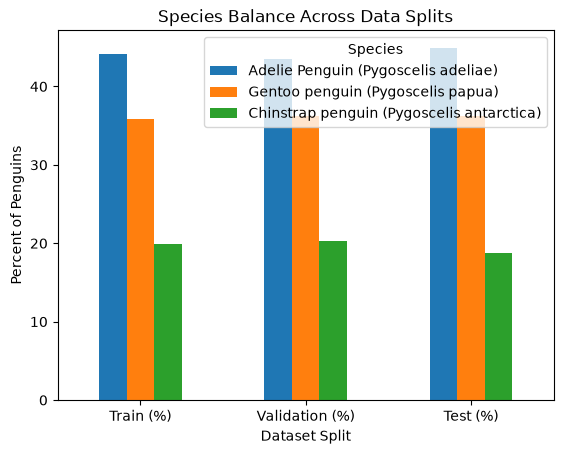

In [19]:
species_balance.T.plot(kind="bar")

plt.title("Species Balance Across Data Splits")
plt.xlabel("Dataset Split")
plt.ylabel("Percent of Penguins")
plt.xticks(rotation=0)
plt.legend(title="Species")
plt.show()

## Important Rule From This Point Forward

The dataset has now passed the **pivot point**.

Anything that learns information from the data must now follow this rule:

**Fit using Train only.**

**Transform Validation and Test using what was learned from Train.**

**Never fit anything using Validation or Test.**

This prevents data leakage and keeps the final evaluation trustworthy.

# Part 7 - Data Preparation: Handle Missing Values

## What This Step Does

Some penguin records are missing measurements or category values.

Machine-learning models cannot work properly with blank (`NaN`) values, so those gaps need to be handled before modeling.

For this analysis:

- missing **numeric values** are filled using the median from the Train set
- missing **text/category values** are filled with `"Missing"`

## Why It Matters

The missing-value replacements must be learned from **Train only**.

Validation and Test data should not influence the values used to prepare the model.

This prevents **data leakage** and keeps the final evaluation more realistic.

## Part 7A - See Missing Values Before Imputation

In [20]:
train_missing_before = X_train.isnull().sum()
train_missing_before = train_missing_before[train_missing_before > 0]

missing_before_table = pd.DataFrame({
    "Column": train_missing_before.index,
    "Missing in Train": train_missing_before.values,
    "Missing (%)": (
        train_missing_before.values / len(X_train) * 100
    ).round(2)
})

missing_before_table

,Column,Missing in Train,Missing (%)
0,Sex,6,2.91
1,delta_15_n,7,3.40
2,delta_13_c,6,2.91


### Understanding the Result

**How to read it:**  
This table shows which columns still contain blank values in the **Train set only**.

`Missing in Train` gives the number of blanks.

`Missing (%)` shows how much of the Train dataset is affected.

**What this result tells us:**  

Only three Train features contain missing data:

- `Sex` → 6 missing values
- `delta_15_n` → 7 missing values
- `delta_13_c` → 6 missing values

Only about **3%** of the Train data is missing in these fields.

**Why it matters:**  
The original dataset had missing values in additional columns, but the dataset was split before imputation.

Some of those missing records therefore landed in Validation or Test instead of Train.

We have not filled anything yet. This step is only identifying what needs to be handled.

## Part 7B - Learn Fill Values From Train

In [21]:
# Find numeric and text columns
num_cols = X_train.select_dtypes(include=[np.number]).columns
text_cols = X_train.select_dtypes(include=["object", "str"]).columns

# Learn numeric medians from TRAIN only
train_num_medians = X_train[num_cols].median()

median_table = pd.DataFrame({
    "Numeric Feature": train_num_medians.index,
    "Train Median Used": train_num_medians.values
})

median_table

,Numeric Feature,Train Median Used
0,bill_length_mm,44.50000
1,bill_depth_mm,17.30000
2,flipper_length_mm,197.00000
3,body_mass_g,4062.50000
4,delta_15_n,8.63701
5,delta_13_c,-25.79366


### Understanding the Result

**How to read it:**  
Each row shows a numeric feature and the Train median that will be used if that feature contains a missing value.

The **median** is the middle value when the numbers are sorted from smallest to largest.

**What this result tells us:**  
Examples of the learned Train medians include:

- `bill_length_mm` → 44.5
- `flipper_length_mm` → 197
- `body_mass_g` → 4062.5

These values were calculated using **Train only**.

**Why it matters:**  
The median is less affected by unusually high or low values than the mean.

More importantly, Validation and Test are not allowed to calculate their own replacement values.

They must use the medians learned from Train so information from those datasets does not leak into model preparation.

## Part 7C - Fill the Missing Values

In [22]:
# Make copies so the original split data is preserved
X_train = X_train.copy()
X_val = X_val.copy()
X_test = X_test.copy()

# Fill numeric values using TRAIN medians
X_train[num_cols] = X_train[num_cols].fillna(train_num_medians)
X_val[num_cols] = X_val[num_cols].fillna(train_num_medians)
X_test[num_cols] = X_test[num_cols].fillna(train_num_medians)

# Fill missing text/category values
X_train[text_cols] = X_train[text_cols].fillna("Missing")
X_val[text_cols] = X_val[text_cols].fillna("Missing")
X_test[text_cols] = X_test[text_cols].fillna("Missing")

In [23]:
missing_after = pd.DataFrame({
    "Dataset": ["Train", "Validation", "Test"],
    "Missing Values Remaining": [
        X_train.isnull().sum().sum(),
        X_val.isnull().sum().sum(),
        X_test.isnull().sum().sum()
    ]
})

missing_after["Status"] = missing_after["Missing Values Remaining"].apply(
    lambda x: "Clean" if x == 0 else "Needs Review"
)

missing_after

,Dataset,Missing Values Remaining,Status
0,Train,0,Clean
1,Validation,0,Clean
2,Test,0,Clean


### Understanding the Result

**How to read it:**  
The table shows the number of missing values remaining after imputation.

A value of `0` means that dataset is now complete and ready for the next step.

**What this result tells us:**  

- Train missing values remaining: **0**
- Validation missing values remaining: **0**
- Test missing values remaining: **0**

All three datasets are now marked **Clean**.

**Why it matters:**  
Machine-learning algorithms cannot reliably work with blank values.

The missing data was handled without deleting any penguins, and the replacement values were learned from Train only.

This keeps the preprocessing consistent while avoiding data leakage.

### Technical Note

**Imputation** means filling a missing value with a reasonable replacement.

For this analysis:

- numeric gaps → Train median
- text/category gaps → `"Missing"`

No rows were deleted.

# Part 8 - Feature Engineering: Encode Categorical Data

## What This Step Does

The dataset still contains some text-based features such as:

- `Island`
- `Sex`
- `Region`
- `Stage`
- `clutch_completion`

Machine-learning models need numeric inputs.

This step converts those categories into numeric columns using **One-Hot Encoding**.

## What Is One-Hot Encoding?

One-Hot Encoding creates separate yes/no columns for each category.

For example, instead of:

`Island = Biscoe`

the model may receive columns such as:

- `Island_Biscoe`
- `Island_Dream`
- `Island_Torgersen`

Each column contains a `1` or `0` depending on whether that category applies to the penguin.

## Why It Matters

Categories such as islands do not have a meaningful numeric ranking.

Giving them fake values such as:

`Biscoe = 1`, `Dream = 2`, `Torgersen = 3`

could incorrectly suggest that one island is somehow "greater" than another.

One-Hot Encoding avoids that problem.

## Part 8A - Identify What Needs Encoding

In [24]:
from sklearn.preprocessing import OneHotEncoder

numeric_cols = X_train.select_dtypes(include=[np.number]).columns

text_cols = [
    col for col in X_train.columns
    if pd.api.types.is_string_dtype(X_train[col])
]

encoding_plan = pd.DataFrame({
    "Column": list(numeric_cols) + list(text_cols),
    "Current Type": (
        ["Numeric"] * len(numeric_cols)
        + ["Text / Category"] * len(text_cols)
    ),
    "Action": (
        ["Keep as numeric"] * len(numeric_cols)
        + ["One-Hot Encode"] * len(text_cols)
    )
})

encoding_plan

,Column,Current Type,Action
0,bill_length_mm,Numeric,Keep as numeric
1,bill_depth_mm,Numeric,Keep as numeric
2,flipper_length_mm,Numeric,Keep as numeric
3,body_mass_g,Numeric,Keep as numeric
4,delta_15_n,Numeric,Keep as numeric
5,delta_13_c,Numeric,Keep as numeric
6,Region,Text / Category,One-Hot Encode
7,Island,Text / Category,One-Hot Encode
8,Stage,Text / Category,One-Hot Encode
9,clutch_completion,Text / Category,One-Hot Encode


### Understanding the Result

**How to read it:**  
The table separates the input features into two groups.

**Numeric features** are already numbers and can stay as they are.

**Text / Category features** need to be converted into numeric form before the model can use them.

**What this result tells us:**  

There are:

- **6 numeric features**
- **5 categorical features**

The numeric measurements are kept.

`Region`, `Island`, `Stage`, `clutch_completion`, and `Sex` need One-Hot Encoding.

**Why it matters:**  
Machine-learning models work with numbers.

However, we cannot simply assign arbitrary numbers such as `Island Biscoe = 1` and `Island Dream = 2`, because that would falsely suggest that one category is greater than another.

One-Hot Encoding converts categories into numeric values without creating a fake ranking.

The target `species` remains separate in `y` and is never encoded as an input feature.

## Part 8B - Fit the Encoder Using Train Only

In [25]:
encoder = OneHotEncoder(
    sparse_output=False,
    handle_unknown="ignore"
)

# Learn category structure from TRAIN only
encoder.fit(X_train[text_cols])

,"sparse_output sparse_output: bool, default=TrueWhen ``True``, it returns a SciPy sparse matrix/arrayin ""Compressed Sparse Row"" (CSR) format... versionadded:: 1.2 `sparse` was renamed to `sparse_output`",False
,"handle_unknown handle_unknown: {'error', 'ignore', 'infrequent_if_exist', 'warn'}, default='error'Specifies the way unknown categories are handled during :meth:`transform`.- 'error' : Raise an error if an unknown category is present during transform.- 'ignore' : When an unknown category is encountered during transform, the resulting one-hot encoded columns for this feature will be all zeros. In the inverse transform, an unknown category will be denoted as None.- 'infrequent_if_exist' : When an unknown category is encountered during transform, the resulting one-hot encoded columns for this feature will map to the infrequent category if it exists. The infrequent category will be mapped to the last position in the encoding. During inverse transform, an unknown category will be mapped to the category denoted `'infrequent'` if it exists. If the `'infrequent'` category does not exist, then :meth:`transform` and :meth:`inverse_transform` will handle an unknown category as with `handle_unknown='ignore'`. Infrequent categories exist based on `min_frequency` and `max_categories`. Read more in the :ref:`User Guide <encoder_infrequent_categories>`.- 'warn' : When an unknown category is encountered during transform a warning is issued, and the encoding then proceeds as described for `handle_unknown=""infrequent_if_exist""`... versionchanged:: 1.1 `'infrequent_if_exist'` was added to automatically handle unknown categories and infrequent categories... versionadded:: 1.6 The option `""warn""` was added in 1.6.",'ignore'
,"categories categories: 'auto' or a list of array-like, default='auto'Categories (unique values) per feature:- 'auto' : Determine categories automatically from the training data.- list : ``categories[i]`` holds the categories expected in the ith column. The passed categories should not mix strings and numeric values within a single feature, and should be sorted in case of numeric values.The used categories can be found in the ``categories_`` attribute... versionadded:: 0.20",'auto'
,"drop drop: {'first', 'if_binary'} or an array-like of shape (n_features,), default=NoneSpecifies a methodology to use to drop one of the categories perfeature. This is useful in situations where perfectly collinearfeatures cause problems, such as when feeding the resulting datainto an unregularized linear regression model.However, dropping one category breaks the symmetry of the originalrepresentation and can therefore induce a bias in downstream models,for instance for penalized linear classification or regression models.- None : retain all features (the default).- 'first' : drop the first category in each feature. If only one category is present, the feature will be dropped entirely.- 'if_binary' : drop the first category in each feature with two categories. Features with 1 or more than 2 categories are left intact.- array : ``drop[i]`` is the category in feature ``X[:, i]`` that should be dropped.When `max_categories` or `min_frequency` is configured to groupinfrequent categories, the dropping behavior is handled after thegrouping... versionadded:: 0.21 The parameter `drop` was added in 0.21... versionchanged:: 0.23 The option `drop='if_binary'` was added in 0.23... versionchanged:: 1.1 Support for dropping infrequent categories.",None
,"dtype dtype: number type, default=np.float64Desired dtype of output.",<class 'numpy.float64'>
,"min_frequency min_frequency: int or float, default=NoneSpecifies the minimum frequency below which a category will beconsidered infrequent.- If `int`, categories with a smaller cardinality will be considered infrequent.- If `float`, categories with a smaller cardinality than `min_frequency * n_samples` will be considered infrequent... versionadded:: 1.1 Read more in the :ref:`User Guide <encoder_infreque

### Why Fit on Train Only?

The encoder needs to learn which categories exist.

That learning is performed using the Train set only.

Validation and Test are then transformed using the category structure learned from Train.

This follows the same no-leakage rule used during imputation.

## Part 8C - Transform Train, Validation, and Test

In [26]:
def encode_split(data):
    encoded = encoder.transform(data[text_cols])

    encoded_df = pd.DataFrame(
        encoded,
        columns=encoder.get_feature_names_out(text_cols),
        index=data.index
    )

    return pd.concat(
        [data[numeric_cols], encoded_df],
        axis=1
    )


X_train_encoded = encode_split(X_train)
X_val_encoded = encode_split(X_val)
X_test_encoded = encode_split(X_test)

In [27]:
encoding_summary = pd.DataFrame({
    "Dataset": ["Train", "Validation", "Test"],
    "Rows": [
        X_train_encoded.shape[0],
        X_val_encoded.shape[0],
        X_test_encoded.shape[0]
    ],
    "Features Before Encoding": [
        X_train.shape[1],
        X_val.shape[1],
        X_test.shape[1]
    ],
    "Features After Encoding": [
        X_train_encoded.shape[1],
        X_val_encoded.shape[1],
        X_test_encoded.shape[1]
    ]
})

encoding_summary

,Dataset,Rows,Features Before Encoding,Features After Encoding
0,Train,206,11,16
1,Validation,69,11,16
2,Test,69,11,16


### Understanding the Result

**How to read it:**  
The table compares the number of features before and after One-Hot Encoding.

The number of rows represents penguins and should not change.

The number of columns can increase because one text category may become several numeric yes/no columns.

**What this result tells us:**  

All three datasets kept the same number of penguins:

- Train = 206
- Validation = 69
- Test = 69

But the number of input features increased from:

**11 → 16**

**Why it matters:**  
Encoding did not add new penguins or new biological information.

It simply changed the existing text categories into a format the model can understand.

This is **feature preparation**, not dimensionality reduction.

LDA will reduce the number of dimensions later.

## Part 8D - See the New Columns

In [28]:
encoded_columns = pd.DataFrame({
    "Encoded Feature": X_train_encoded.columns
})

encoded_columns

,Encoded Feature
0,bill_length_mm
1,bill_depth_mm
2,flipper_length_mm
3,body_mass_g
4,delta_15_n
5,delta_13_c
6,Region_Anvers
7,Island_Biscoe
8,Island_Dream
9,Island_Torgersen


### Understanding the Result

**How to read it:**  
The table lists the 16 features that now enter the next stage of the analysis.

The original numeric measurements are still present.

The text categories have been expanded into separate binary columns.

For example, `Sex` became:

- `Sex_FEMALE`
- `Sex_MALE`
- `Sex_Missing`

**What this result tells us:**  
A value of:

- `1` means the category applies to that penguin
- `0` means it does not

For example, a female penguin would have:

`Sex_FEMALE = 1`

and:

`Sex_MALE = 0`

**Why it matters:**  
The entire feature matrix is now numeric.

That means the data is ready for the later correlation, standardization, and LDA steps without inventing a fake ranking between categories.

### Technical Note

`handle_unknown="ignore"` prevents the encoder from crashing if Validation or Test contains a category that was not seen during training.

The encoder still learns its category structure from Train only.

# Part 9 - Feature Engineering: Correlation Matrix

## What This Step Does

Now that all model inputs are numeric, we can check how strongly the features relate to one another.

This is called **correlation**.

Correlation ranges from:

- **+1.00** = two features increase together very strongly
- **0.00** = little or no linear relationship
- **-1.00** = one feature tends to increase while the other decreases

## Why It Matters

Highly correlated features may contain overlapping information.

For example, if larger penguins tend to have both longer flippers and greater body mass, those two features may partly tell the same story.

This step is only a **diagnostic**.

LDA can still run without removing correlated features.

## Part 9A - Full Correlation Matrix

In [29]:
correlation_matrix = X_train_encoded.corr()

correlation_matrix.round(2)

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,delta_15_n,delta_13_c,Region_Anvers,Island_Biscoe,Island_Dream,Island_Torgersen,"Stage_Adult, 1 Egg Stage",clutch_completion_No,clutch_completion_Yes,Sex_FEMALE,Sex_MALE,Sex_Missing
bill_length_mm,1.00,-0.17,0.68,0.61,-0.05,0.17,NaN,0.22,0.03,-0.36,NaN,0.08,-0.08,-0.37,0.41,-0.11
bill_depth_mm,-0.17,1.00,-0.57,-0.49,0.60,0.46,NaN,-0.63,0.49,0.24,NaN,0.11,-0.11,-0.37,0.37,0.01
flipper_length_mm,0.68,-0.57,1.00,0.86,-0.45,-0.34,NaN,0.59,-0.40,-0.31,NaN,-0.11,0.11,-0.22,0.25,-0.08
body_mass_g,0.61,-0.49,0.86,1.00,-0.50,-0.36,NaN,0.61,-0.45,-0.26,NaN,-0.11,0.11,-0.39,0.42,-0.08
delta_15_n,-0.05,0.60,-0.45,-0.50,1.00,0.57,NaN,-0.57,0.62,-0.04,NaN,0.14,-0.14,-0.12,0.14,-0.07
delta_13_c,0.17,0.46,-0.34,-0.36,0.57,1.00,NaN,-0.53,0.60,-0.07,NaN,0.13,-0.13,-0.07,0.06,0.00
Region_Anvers,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Island_Biscoe,0.22,-0.63,0.59,0.61,-0.57,-0.53,NaN,1.00,-0.75,-0.40,NaN,-0.14,0.14,0.03,-0.01,-0.06
Island_Dream,0.03,0.49,-0.40,-0.45,0.62,0.60,NaN,-0.75,1.00,-0.30,NaN,0.15,-0.15,-0.04,0.06,-0.07
Island_Torgersen,-0.36,0.24,-0.31,-0.26,-0.04,-0.07,NaN,-0.40,-0.30,1.00,NaN,0.00,-0.00,0.01,-0.07,0.18


### How to Read This Table

Each number compares two features.

Values close to:

- **+1** = strong positive relationship
- **-1** = strong negative relationship
- **0** = weak relationship

The diagonal is always `1.00` because every feature is perfectly correlated with itself.

Some encoded columns may show `NaN`.

That usually means the column is constant in the Train set and has no variation to compare.

## Part 9B - Cleaner Numeric-Only Table

In [30]:
numeric_correlation = X_train_encoded[list(numeric_cols)].corr()

numeric_correlation.round(2)

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,delta_15_n,delta_13_c
bill_length_mm,1.00,-0.17,0.68,0.61,-0.05,0.17
bill_depth_mm,-0.17,1.00,-0.57,-0.49,0.60,0.46
flipper_length_mm,0.68,-0.57,1.00,0.86,-0.45,-0.34
body_mass_g,0.61,-0.49,0.86,1.00,-0.50,-0.36
delta_15_n,-0.05,0.60,-0.45,-0.50,1.00,0.57
delta_13_c,0.17,0.46,-0.34,-0.36,0.57,1.00


### What This Means

The numeric-only table is easier to interpret because it focuses on the original measurements.

A high positive value means two measurements tend to increase together.

A negative value means that when one measurement increases, the other tends to decrease.

Strong relationships can indicate that multiple features contain some of the same information.

## Part 9C - Heatmap

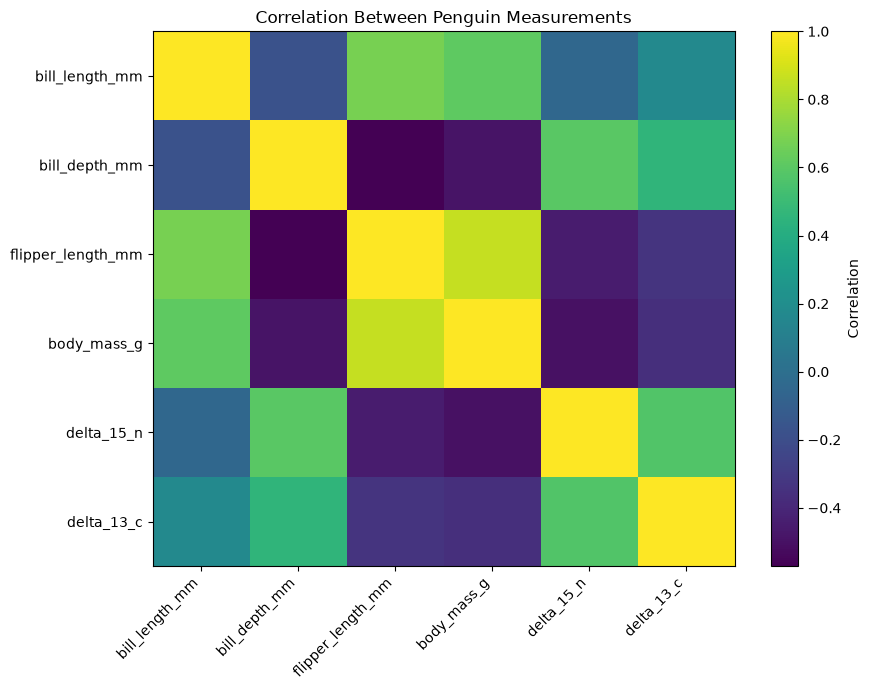

In [31]:
plt.figure(figsize=(9, 7))

plt.imshow(
    numeric_correlation,
    aspect="auto"
)

plt.colorbar(label="Correlation")

plt.xticks(
    range(len(numeric_correlation.columns)),
    numeric_correlation.columns,
    rotation=45,
    ha="right"
)

plt.yticks(
    range(len(numeric_correlation.index)),
    numeric_correlation.index
)

plt.title("Correlation Between Penguin Measurements")
plt.tight_layout()
plt.show()

### How to Read This Heatmap

The heatmap shows the same correlation values as the table, but visually.

Features with stronger relationships stand out more clearly.

The important part is not the exact shade.

The goal is to quickly identify which measurements move strongly together or in opposite directions.

## Part 9D - Show Strongest Relationships

In [32]:
corr_pairs = (
    numeric_correlation
    .where(
        np.triu(
            np.ones(numeric_correlation.shape),
            k=1
        ).astype(bool)
    )
    .stack()
    .reset_index()
)

corr_pairs.columns = [
    "Feature 1",
    "Feature 2",
    "Correlation"
]

strongest_relationships = (
    corr_pairs
    .assign(
        Absolute_Correlation=lambda x: x["Correlation"].abs()
    )
    .sort_values(
        "Absolute_Correlation",
        ascending=False
    )
    .drop(columns="Absolute_Correlation")
    .head(5)
    .round(2)
)

strongest_relationships

,Feature 1,Feature 2,Correlation
15,flipper_length_mm,body_mass_g,0.86
2,bill_length_mm,flipper_length_mm,0.68
3,bill_length_mm,body_mass_g,0.61
10,bill_depth_mm,delta_15_n,0.60
29,delta_15_n,delta_13_c,0.57


### Key Finding

This table shows the strongest relationships between the numeric penguin measurements.

The strongest pair is especially important because it suggests the two measurements may contain overlapping information.

Correlation does **not** mean one feature causes the other.

It only shows that they tend to move together.

### Key Finding

The strongest relationship is between `flipper_length_mm` and `body_mass_g`, with a correlation of **0.86**.

This means heavier penguins also tend to have longer flippers.

These two measurements may contain some overlapping information.

Some encoded columns show `NaN` correlations because they contain only one value in the Train set, meaning they have no variation.

Correlation shows association, not cause.

# Part 10 - Feature Engineering: Standardization

## What This Step Does

The input features currently use very different numeric scales.

For example:

- `body_mass_g` contains values in the thousands
- `bill_length_mm` contains values around the tens
- encoded categories contain values such as 0 and 1

Standardization rescales every feature so they are on a comparable scale.

## What Is Standardization?

Standardization transforms each value based on:

**how far it is from the average**

After scaling, the Train data should have approximately:

- **mean = 0**
- **standard deviation = 1**

## Why It Matters

Without scaling, features with larger raw numbers can have too much influence simply because of their units.

Standardization gives the features a more equal starting point before LDA.

The scaler must be **fit using Train only**.

Validation and Test use the scaling rules learned from Train.

## Part 10A - Scale the Data

In [33]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

# Learn scaling rules from TRAIN only
X_train_scaled = scaler.fit_transform(X_train_encoded)

# Apply TRAIN scaling rules to Validation and Test
X_val_scaled = scaler.transform(X_val_encoded)
X_test_scaled = scaler.transform(X_test_encoded)

## Part 10B - Scaling Summary

In [34]:
scaling_summary = pd.DataFrame({
    "Dataset": ["Train", "Validation", "Test"],
    "Rows": [
        X_train_scaled.shape[0],
        X_val_scaled.shape[0],
        X_test_scaled.shape[0]
    ],
    "Features": [
        X_train_scaled.shape[1],
        X_val_scaled.shape[1],
        X_test_scaled.shape[1]
    ],
    "Overall Mean": [
        X_train_scaled.mean(),
        X_val_scaled.mean(),
        X_test_scaled.mean()
    ],
    "Overall Std": [
        X_train_scaled.std(),
        X_val_scaled.std(),
        X_test_scaled.std()
    ]
})

scaling_summary.round(3)

,Dataset,Rows,Features,Overall Mean,Overall Std
0,Train,206,16,-0.000,0.935
1,Validation,69,16,-0.012,0.883
2,Test,69,16,-0.027,0.986


### How to Read This Table

The number of rows and features did not change.

Standardization changes the **scale of the values**, not the structure of the dataset.

The Train mean should be very close to **0** because the scaler learned from Train.

Validation and Test do not need to have an exact mean of 0 because they are being transformed using Train's scaling rules.

## Part 10C - Show Before vs After

In [35]:
X_train_scaled_df = pd.DataFrame(
    X_train_scaled,
    columns=X_train_encoded.columns,
    index=X_train_encoded.index
)

In [36]:
scale_comparison = pd.DataFrame({
    "Feature": [
        "bill_length_mm",
        "flipper_length_mm",
        "body_mass_g"
    ],
    "Original Mean": [
        X_train_encoded["bill_length_mm"].mean(),
        X_train_encoded["flipper_length_mm"].mean(),
        X_train_encoded["body_mass_g"].mean()
    ],
    "Original Std": [
        X_train_encoded["bill_length_mm"].std(),
        X_train_encoded["flipper_length_mm"].std(),
        X_train_encoded["body_mass_g"].std()
    ],
    "Scaled Mean": [
        X_train_scaled_df["bill_length_mm"].mean(),
        X_train_scaled_df["flipper_length_mm"].mean(),
        X_train_scaled_df["body_mass_g"].mean()
    ],
    "Scaled Std": [
        X_train_scaled_df["bill_length_mm"].std(),
        X_train_scaled_df["flipper_length_mm"].std(),
        X_train_scaled_df["body_mass_g"].std()
    ]
})

scale_comparison.round(3)

,Feature,Original Mean,Original Std,Scaled Mean,Scaled Std
0,bill_length_mm,44.230,5.570,-0.0,1.002
1,flipper_length_mm,200.898,14.407,0.0,1.002
2,body_mass_g,4225.728,810.228,-0.0,1.002


### What This Means

Before scaling, the features used very different units and ranges.

For example, body mass may be measured in the thousands while bill length is measured in the tens.

After scaling:

- feature averages move close to **0**
- feature spread moves close to **1**

This allows LDA to compare the features more fairly.

## Part 10D - Visual Check

In [37]:
original_ranges = (
    X_train_encoded[list(numeric_cols)].max()
    - X_train_encoded[list(numeric_cols)].min()
)

scaled_ranges = (
    X_train_scaled_df[list(numeric_cols)].max()
    - X_train_scaled_df[list(numeric_cols)].min()
)

range_comparison = pd.DataFrame({
    "Before Standardization": original_ranges,
    "After Standardization": scaled_ranges
})

range_comparison

,Before Standardization,After Standardization
bill_length_mm,26.50000,4.768873
bill_depth_mm,8.40000,4.161413
flipper_length_mm,59.00000,4.105173
body_mass_g,3450.00000,4.268435
delta_15_n,2.39324,4.399572
delta_13_c,3.10877,3.954681


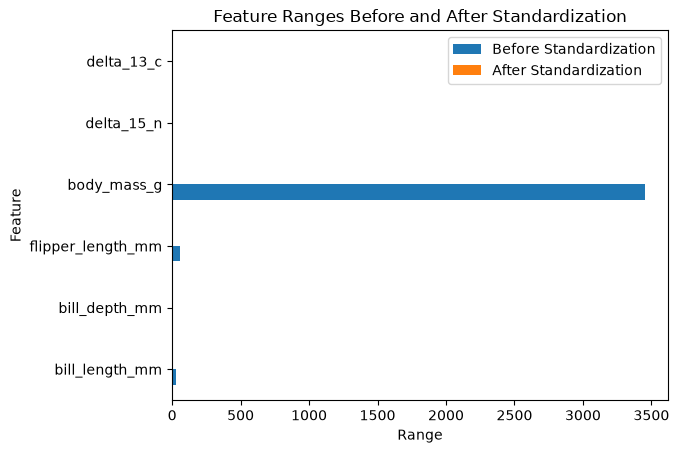

In [38]:
range_comparison.plot(kind="barh")

plt.title("Feature Ranges Before and After Standardization")
plt.xlabel("Range")
plt.ylabel("Feature")
plt.show()

### How to Read This Graph

Before standardization, some measurements have much larger numeric ranges than others.

After standardization, the feature scales are much more comparable.

This helps prevent large-unit features from dominating the LDA calculation simply because their raw numbers are bigger.

### Key Finding

Before standardization, the numeric features used very different scales.

`body_mass_g` had a much larger numeric range than the other measurements, which could give it too much influence simply because of its units.

After standardization, the features are placed on a much more comparable scale.

The Train mean is approximately **0**, as expected.

The overall Train standard deviation is slightly below 1 because some encoded features are constant and contain no variation.

# Part 11 - Modeling: Apply Linear Discriminant Analysis

## What This Step Does

The prepared dataset currently contains **16 numeric input features**.

Linear Discriminant Analysis (LDA) will combine those features into a much smaller number of new features called **Linear Discriminants**.

For this dataset there are 3 species:

- Adelie
- Gentoo
- Chinstrap

LDA can create a maximum of:

**Number of classes - 1**

Therefore:

**3 - 1 = 2 discriminants**

These will be called:

- `LD1`
- `LD2`

## Why It Matters

LDA does not simply look for overall variation.

It uses the known species labels to find directions that separate the species as clearly as possible.

The goal is to reduce the dataset while preserving information that is useful for classification.

## Part 11A - Calculate All Available Discriminants

In [39]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA

lda_explorer = LDA()

# FIT using Train only
X_train_lda_all = lda_explorer.fit_transform(
    X_train_scaled,
    y_train
)

# Validation and Test only use what LDA learned from Train
X_val_lda_all = lda_explorer.transform(X_val_scaled)
X_test_lda_all = lda_explorer.transform(X_test_scaled)

explained_separation_ratio = lda_explorer.explained_variance_ratio_
cumulative_separation = np.cumsum(explained_separation_ratio)
scalings = lda_explorer.scalings_

In [40]:
lda_shape_summary = pd.DataFrame({
    "Dataset": [
        "Train",
        "Validation",
        "Test"
    ],
    "Rows": [
        X_train_lda_all.shape[0],
        X_val_lda_all.shape[0],
        X_test_lda_all.shape[0]
    ],
    "Features Before LDA": [
        X_train_scaled.shape[1],
        X_val_scaled.shape[1],
        X_test_scaled.shape[1]
    ],
    "Discriminants After LDA": [
        X_train_lda_all.shape[1],
        X_val_lda_all.shape[1],
        X_test_lda_all.shape[1]
    ]
})

lda_shape_summary

,Dataset,Rows,Features Before LDA,Discriminants After LDA
0,Train,206,16,2
1,Validation,69,16,2
2,Test,69,16,2


### What This Means

LDA reduced the model inputs from:

**16 features → 2 discriminants**

The number of penguin records did not change.

LDA created two new blended features, `LD1` and `LD2`, that are designed specifically to separate the three species.

This is the actual dimensionality-reduction step.

## Part 11B - Explained Separation

In [41]:
lda_separation_summary = pd.DataFrame({
    "Discriminant": [
        f"LD{i+1}"
        for i in range(len(explained_separation_ratio))
    ],
    "Separation Explained (%)":
        explained_separation_ratio * 100,
    "Cumulative Separation (%)":
        cumulative_separation * 100
})

lda_separation_summary.round(2)

,Discriminant,Separation Explained (%),Cumulative Separation (%)
0,LD1,81.02,81.02
1,LD2,18.98,100.00


### How to Read This Table

`Separation Explained (%)` tells us how much of the species-separating information each discriminant captures.

`Cumulative Separation (%)` shows the running total.

If LD1 explains most of the separation, it means a large portion of the species differences can already be represented along a single new axis.

LD2 adds the remaining separation information.

## Part 11C - Which Features Drive LD1 and LD2?

In [42]:
scalings_df = pd.DataFrame(
    scalings.T,
    columns=X_train_encoded.columns,
    index=[
        f"LD{i+1}"
        for i in range(len(explained_separation_ratio))
    ]
)

scalings_df.round(3)

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,delta_15_n,delta_13_c,Region_Anvers,Island_Biscoe,Island_Dream,Island_Torgersen,"Stage_Adult, 1 Egg Stage",clutch_completion_No,clutch_completion_Yes,Sex_FEMALE,Sex_MALE,Sex_Missing
LD1,0.557,-1.850,1.512,0.949,-0.227,0.113,0.0,0.320,-0.106,-0.140,0.0,0.041,-0.041,0.123,-0.185,0.184
LD2,-1.929,0.102,-0.238,0.795,-0.132,-0.711,-0.0,0.249,-0.404,0.138,-0.0,-0.018,0.018,-0.159,0.151,0.027


In [43]:
top_lda_drivers = []

for ld in scalings_df.index:
    strongest_features = (
        scalings_df.loc[ld]
        .abs()
        .sort_values(ascending=False)
        .head(5)
        .index
    )

    for feature in strongest_features:
        top_lda_drivers.append({
            "Discriminant": ld,
            "Feature": feature,
            "Weight": scalings_df.loc[ld, feature]
        })

top_lda_drivers = pd.DataFrame(top_lda_drivers)

top_lda_drivers.round(3)

,Discriminant,Feature,Weight
0,LD1,bill_depth_mm,-1.850
1,LD1,flipper_length_mm,1.512
2,LD1,body_mass_g,0.949
3,LD1,bill_length_mm,0.557
4,LD1,Island_Biscoe,0.320
5,LD2,bill_length_mm,-1.929
6,LD2,body_mass_g,0.795
7,LD2,delta_13_c,-0.711
8,LD2,Island_Dream,-0.404
9,LD2,Island_Biscoe,0.249


### How to Read the Feature Weights

Larger absolute weights mean a feature contributes more strongly to that discriminant.

The sign (`+` or `-`) shows the direction of the relationship.

For determining importance, the size of the weight matters more than whether it is positive or negative.

This helps explain which original penguin measurements are doing most of the work when LDA separates the species.

### Key Finding

LDA successfully reduced the model from **16 input features to 2 discriminants**.

`LD1` captures **81.02%** of the species-separating information, while `LD2` captures the remaining **18.98%**.

The strongest drivers of `LD1` are:

- `bill_depth_mm`
- `flipper_length_mm`
- `body_mass_g`

The strongest driver of `LD2` is `bill_length_mm`.

The positive or negative sign does not mean a feature is good or bad.

The **size of the weight** shows how strongly the feature contributes to that discriminant.

## Part 11D - Visualize Species Separation

The two LDA discriminants can now be plotted against each other.

Each point represents one penguin.

The graph answers:

**"After combining all 16 features into LD1 and LD2, do the three species form separate groups?"**

Better separation means the reduced features are preserving useful information for classification.

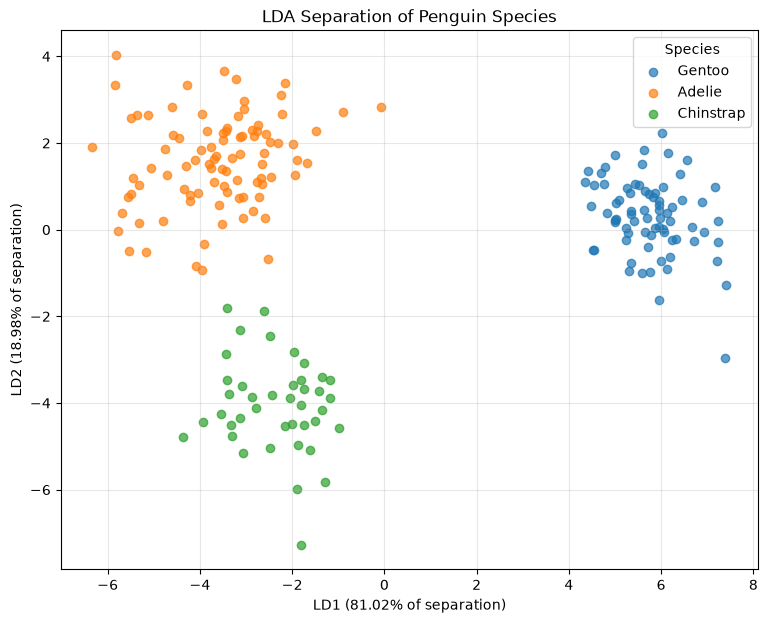

In [44]:
lda_plot = pd.DataFrame({
    "LD1": X_train_lda_all[:, 0],
    "LD2": X_train_lda_all[:, 1],
    "Species": y_train.reset_index(drop=True)
})

species_name_map = {
    "Adelie Penguin (Pygoscelis adeliae)": "Adelie",
    "Gentoo penguin (Pygoscelis papua)": "Gentoo",
    "Chinstrap penguin (Pygoscelis antarctica)": "Chinstrap"
}

lda_plot["Species Short"] = lda_plot["Species"].replace(species_name_map)

plt.figure(figsize=(9, 7))

for species in lda_plot["Species Short"].unique():
    group = lda_plot[lda_plot["Species Short"] == species]

    plt.scatter(
        group["LD1"],
        group["LD2"],
        label=species,
        alpha=0.7
    )

plt.xlabel("LD1 (81.02% of separation)")
plt.ylabel("LD2 (18.98% of separation)")
plt.title("LDA Separation of Penguin Species")
plt.legend(title="Species")
plt.grid(alpha=0.3)
plt.show()

### How to Read This Graph

Each dot represents one penguin.

Dots that appear close together have similar LDA profiles.

If the species form separate clusters, LDA has successfully found combinations of features that distinguish the groups.

If two species overlap heavily, the model may have more difficulty telling them apart.

`LD1` contains most of the separation information, while `LD2` adds the remaining detail needed to distinguish the species.

In [45]:
species_centers = (
    lda_plot
    .groupby("Species Short")[["LD1", "LD2"]]
    .mean()
    .round(2)
)

species_centers

,LD1,LD2
Species Short,,
Adelie,-3.62,1.58
Chinstrap,-2.36,-4.05
Gentoo,5.76,0.30


### What This Table Means

This table shows the average location of each species in the LDA space.

Species with averages that are far apart are easier for LDA to separate.

The scatter plot shows the individual penguins, while this table gives a simpler summary of where each species is centered.

### Key Finding

The LDA projection shows three clearly separated species groups.

- Gentoo separates strongly along `LD1`.
- Adelie and Chinstrap are both on the negative side of `LD1`, but `LD2` helps separate them vertically.
- There is very little visible overlap between the three groups in the Train data.

This suggests that the two LDA discriminants preserve strong information for distinguishing penguin species.

The species-center table confirms that each species occupies a different average location in the reduced LDA space.

# Part 12 - Evaluation: Choose the Best Number of LDA Components

## What This Step Does

LDA can produce a maximum of **2 discriminants** for this dataset.

Now we test whether the model performs better using:

- only `LD1`
- both `LD1` and `LD2`

A simple Logistic Regression classifier is trained on each LDA version.

The classifier is then evaluated using the **Validation set**.

## Why It Matters

Keeping more components is not automatically better.

The Validation set lets us check whether the extra discriminant actually improves classification performance.

The Test set is still untouched.

It will only be used once after the best component count has been chosen.

## Part 12A - Test 1 vs 2 Discriminants

In [46]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

results = []

for n in [1, 2]:

    # Fit LDA using TRAIN only
    lda_n = LDA(n_components=n)

    X_train_lda_n = lda_n.fit_transform(
        X_train_scaled,
        y_train
    )

    X_val_lda_n = lda_n.transform(
        X_val_scaled
    )

    # Train a simple classifier on TRAIN
    clf = LogisticRegression(
        max_iter=1000,
        random_state=42
    )

    clf.fit(
        X_train_lda_n,
        y_train
    )

    # Evaluate on VALIDATION
    val_predictions = clf.predict(X_val_lda_n)

    val_accuracy = accuracy_score(
        y_val,
        val_predictions
    )

    results.append({
        "LDA Components": n,
        "Validation Accuracy": val_accuracy,
        "Validation Accuracy (%)": val_accuracy * 100
    })

results_df = pd.DataFrame(results)

results_df[
    ["LDA Components", "Validation Accuracy (%)"]
].round(2)

,LDA Components,Validation Accuracy (%)
0,1,89.86
1,2,100.00


### How to Read This Table

Each row tests a different amount of dimensionality reduction.

A higher Validation Accuracy means that version of the LDA representation helped the classifier distinguish species more successfully.

This lets the Validation set answer:

**"Do we actually gain anything by keeping LD2?"**

## Part 12B - Pick the Best Setting

In [47]:
best_n = int(
    results_df.loc[
        results_df["Validation Accuracy"].idxmax(),
        "LDA Components"
    ]
)

best_validation_accuracy = (
    results_df["Validation Accuracy"].max() * 100
)

best_component_summary = pd.DataFrame({
    "Selected LDA Components": [best_n],
    "Best Validation Accuracy (%)": [
        best_validation_accuracy
    ]
})

best_component_summary.round(2)

,Selected LDA Components,Best Validation Accuracy (%)
0,2,100.0


### What This Means

The selected number of LDA components is the setting that achieved the highest Validation accuracy.

This setting will be carried forward into the final model.

The Test set has still not been used to make this decision.

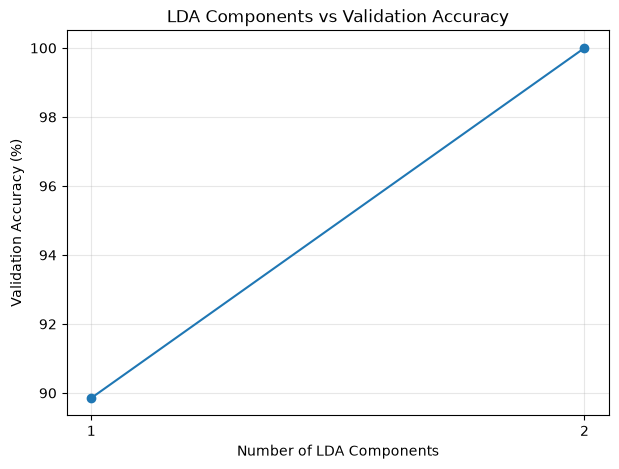

In [48]:
plt.figure(figsize=(7, 5))

plt.plot(
    results_df["LDA Components"],
    results_df["Validation Accuracy (%)"],
    marker="o"
)

plt.title("LDA Components vs Validation Accuracy")
plt.xlabel("Number of LDA Components")
plt.ylabel("Validation Accuracy (%)")
plt.xticks([1, 2])
plt.grid(alpha=0.3)

plt.show()

### How to Read This Graph

The graph shows whether adding the second discriminant improves Validation performance.

If accuracy rises from 1 to 2 components, `LD2` adds useful information.

If accuracy stays the same, the simpler one-component representation may already contain enough information.

The final choice is based on Validation performance, not on the Test set.

### Key Finding

Using both LDA discriminants produced the best Validation performance.

- **1 component:** 89.86% accuracy
- **2 components:** 100.00% accuracy

Keeping `LD2` improved Validation accuracy by about **10 percentage points**.

This shows that although `LD1` contains most of the separation information, `LD2` adds important information for distinguishing the species.

The final model will therefore use **2 LDA components**.

# Part 13 - Final Evaluation on Test

## What This Step Does

The model settings have now been chosen.

Validation selected:

**2 LDA components**

The Test set can finally be used to estimate how well the finished pipeline performs on unseen data.

The final process is:

1. fit LDA with 2 components using Train
2. transform Train and Test
3. train the classifier using Train
4. make predictions on Test
5. calculate final Test accuracy

## Why Test Is Used Only Once

The Test set is meant to act like new data that the model has never seen before.

If we check the Test score and then change the model because of that result, the Test set would become part of model tuning.

That would make the final score less trustworthy.

## Part 13A - Final Test Evaluation

In [49]:
# Fit final LDA using the number chosen from Validation
lda_final = LDA(n_components=best_n)

X_train_final = lda_final.fit_transform(
    X_train_scaled,
    y_train
)

X_test_final = lda_final.transform(
    X_test_scaled
)

# Train final classifier on TRAIN
clf_final = LogisticRegression(
    max_iter=1000,
    random_state=42
)

clf_final.fit(
    X_train_final,
    y_train
)

# Final TEST prediction
test_predictions = clf_final.predict(
    X_test_final
)

test_accuracy = accuracy_score(
    y_test,
    test_predictions
)

print("LDA components used:", best_n)
print(f"Final Test Accuracy: {test_accuracy * 100:.2f}%")

LDA components used: 2
Final Test Accuracy: 100.00%


In [50]:
final_summary = pd.DataFrame({
    "Stage": [
        "Validation Best",
        "Final Test"
    ],
    "LDA Components": [
        best_n,
        best_n
    ],
    "Accuracy (%)": [
        best_validation_accuracy,
        test_accuracy * 100
    ]
})

final_summary.round(2)

,Stage,LDA Components,Accuracy (%)
0,Validation Best,2,100.0
1,Final Test,2,100.0


### How to Read This Table

Validation accuracy was used to choose the model settings.

Test accuracy is the final independent check.

If the Test result is reasonably close to the Validation result, that suggests the model generalizes well to unseen data.

A lower Test result does not automatically mean the model failed.

Validation and Test contain different penguins, so some difference is expected.

### Important Interpretation

A very high Validation score is encouraging, but it does not guarantee perfect performance on new data.

The Test result provides the more important final check because the Test set was not used to choose the model configuration.

For a larger real-world project, performance would also be evaluated using more data and repeated validation methods.

### Final Evaluation Finding

The final model achieved:

- **Validation Accuracy: 100.00%**
- **Test Accuracy: 100.00%**
- **LDA Components Used: 2**

The Test set was not used to choose the number of LDA components.

This makes the Test result the final independent evaluation of the completed pipeline.

For this specific split of the Palmer Penguins dataset, all Test observations were classified correctly.

A 100% Test result does **not** mean the model is guaranteed to be perfect on all future data.

This dataset is relatively small and the species are strongly separable using the available measurements. A real production system would still require additional data, repeated validation, and monitoring on new observations.

## Part 13B - Prediction Breakdown

Accuracy gives one overall score.

A **confusion matrix** shows which species were predicted correctly and where mistakes occurred.

- Rows = actual species
- Columns = predicted species
- Numbers on the diagonal = correct predictions
- Numbers outside the diagonal = mistakes

In [51]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

species_order = [
    "Adelie Penguin (Pygoscelis adeliae)",
    "Gentoo penguin (Pygoscelis papua)",
    "Chinstrap penguin (Pygoscelis antarctica)"
]

cm = confusion_matrix(
    y_test,
    test_predictions,
    labels=species_order
)

cm_table = pd.DataFrame(
    cm,
    index=["Actual Adelie", "Actual Gentoo", "Actual Chinstrap"],
    columns=["Predicted Adelie", "Predicted Gentoo", "Predicted Chinstrap"]
)

cm_table

,Predicted Adelie,Predicted Gentoo,Predicted Chinstrap
Actual Adelie,31,0,0
Actual Gentoo,0,25,0
Actual Chinstrap,0,0,13


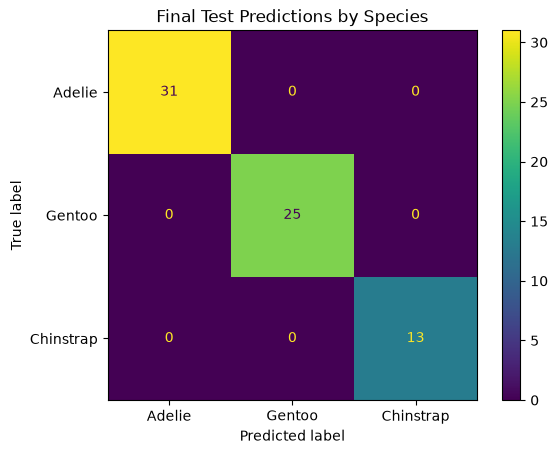

In [52]:
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Adelie", "Gentoo", "Chinstrap"]
)

disp.plot()
plt.title("Final Test Predictions by Species")
plt.show()

### How to Read This Result

Correct predictions appear along the main diagonal.

Any values outside the diagonal represent classification mistakes.

Because the final Test accuracy was **100%**, all Test penguins should appear on the diagonal and no species should be misclassified.

This provides a more detailed view of the final accuracy score.

# Part 14 - When LDA Is Appropriate

LDA is useful when class labels are already available and the goal is to create a smaller representation that separates those classes.

### LDA Is a Good Choice When

- the target classes are known
- classification is the goal
- strong class separation is useful
- a compact representation is needed

### LDA May Not Be the Best Choice When

- no target labels exist → PCA may be more appropriate
- more components are required than `classes - 1`
- the classes have very different covariance structures
- the relationships are strongly nonlinear

### PCA vs LDA

**PCA asks:**  
"Where is the most variation?"

**LDA asks:**  
"Where are the classes separated most clearly?"

For this project, LDA is appropriate because the penguin species labels are already known and the goal is species separation.

# Part 15 - Deployment: Export the Reduced Dataset

The final LDA representation can now be saved for later use.

Instead of storing all 16 encoded model features, the exported dataset contains:

- `LD1`
- `LD2`
- `species`

This creates a compact dataset that can be used for downstream model training or analysis.

In [53]:
import os

df_lda_result = pd.DataFrame(
    X_train_final,
    columns=["LD1", "LD2"]
)

df_lda_result["species"] = y_train.reset_index(drop=True).values

output_path = "../Data/penguins_lda_reduced.csv"

df_lda_result.to_csv(
    output_path,
    index=False
)

print("Saved:", output_path)
print("Rows:", df_lda_result.shape[0])
print("Columns:", df_lda_result.shape[1])

Saved: ../Data/penguins_lda_reduced.csv
Rows: 206
Columns: 3


In [54]:
export_summary = pd.DataFrame({
    "Output File": ["penguins_lda_reduced.csv"],
    "Rows Saved": [df_lda_result.shape[0]],
    "Columns Saved": [df_lda_result.shape[1]],
    "Contents": ["LD1, LD2, species"]
})

export_summary

,Output File,Rows Saved,Columns Saved,Contents
0,penguins_lda_reduced.csv,206,3,"LD1, LD2, species"


# Part 16 - Quality and Risk Check

Before considering the analysis complete, the workflow was checked for common LDA mistakes.

### Checks Completed

- **Target leakage avoided**  
  `species` was kept separately as the target (`y`) and never entered the input features (`X`).

- **Maximum LDA size respected**  
  With 3 species, LDA can create a maximum of 2 discriminants.

- **Features standardized before LDA**  
  Measurements using very different units were placed on comparable scales.

- **Training-only preprocessing used**  
  Imputation, encoding, scaling, and LDA were learned from the Train set.

- **Validation used for model selection**  
  The number of LDA components was chosen using Validation performance.

- **Test preserved for final evaluation**  
  The Test set was not used to choose model settings.

- **LDA weights were displayed correctly**  
  `scalings_` was transposed before building the feature-weight table.

### Why This Matters

These checks reduce the risk of producing an accuracy score that looks strong because of leakage or incorrect preprocessing rather than real predictive performance.

# Activity Complete ✅

## LDA Analysis - Final Results

The Palmer Penguins dataset was prepared and evaluated using Linear Discriminant Analysis (LDA) to determine whether the original feature set could be reduced while preserving strong species separation.

### Final Results

- **Original dataset:** 344 penguins
- **Original columns:** 17
- **Columns after removing ID/date/reference fields:** 12
- **Input features before encoding:** 11
- **Features after encoding:** 16
- **Maximum possible LDA discriminants:** 2
- **Selected LDA discriminants:** 2
- **LD1 separation explained:** 81.02%
- **LD2 separation explained:** 18.98%
- **Validation accuracy:** 100.00%
- **Final Test accuracy:** 100.00%
- **Final Test errors:** 0 of 69 penguins
- **Reduced Train dataset:** 206 rows × 3 columns

## What the Results Mean

LDA reduced **16 model features down to only 2 discriminants** while retaining enough information to separate all three penguin species in the final Test set.

`LD1` carried most of the species-separating information, while `LD2` added important information that improved Validation accuracy from **89.86% to 100.00%**.

The final Test set contained 69 previously held-out penguins, and all 69 were classified correctly.

## Important Limitation

The 100% Test accuracy applies to this specific dataset and split.

It does not guarantee perfect performance on future penguin observations.

The dataset is relatively small and the three species are strongly separated by the available measurements.

For a production system, performance should also be tested using larger datasets, repeated cross-validation, and future incoming observations.

## Recommended Next Steps

If this analysis were moved beyond the classroom into a real deployment, the next steps would be:

1. **Collect more observations**  
   More penguins would provide a stronger test of whether the model generalizes.

2. **Use repeated cross-validation**  
   This would check whether the strong accuracy remains consistent across different data splits.

3. **Monitor class balance**  
   Chinstrap has fewer observations than Adelie and Gentoo, so future data collection should avoid increasing that imbalance.

4. **Monitor new data for drift**  
   Future measurements may differ from the historical data used to build this model.

5. **Investigate unexpected errors if they appear**  
   New misclassifications could indicate unusual measurements, changing data quality, or a population not represented in the original dataset.

### Client Takeaway

The current results support using the two-dimensional LDA representation as a compact way to separate the three penguin species in this dataset.

The model performed extremely well under the current evaluation, but future data should still be monitored before treating the result as production-ready.